# Tugas Praktikum - Multiple Linear Regression Biaya Medis

**Nama:** Agus  
**NIM:** 244107020049

[Sumber modul](https://polinema.gitbook.io/jti-modul-praktikum-pembelajaran-mesin-2025-2026/js06-regresi/tugas-praktikum)

## Deskripsi dan variabel

Target `charges` adalah biaya medis personal. Fitur numerik: `age` (usia), `bmi` (indeks massa tubuh), `children` (jumlah anak). Fitur kategori: `sex`, `smoker`, dan `region`. Identitas baris tidak digunakan. Dataset asli berisi 1.338 baris; duplikat identik dibuang sebelum split 80:20. Encoding dan scaling dipelajari hanya dari data latih melalui pipeline.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay
np.random.seed(42)
sns.set_theme(style='whitegrid')
print('Kernel:', sys.executable)

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
data = pd.read_csv('data/insurance.csv')
print('Ukuran awal:', data.shape, '| Duplikat:', data.duplicated().sum())
data = data.drop_duplicates().reset_index(drop=True)
display(data.head())
display(data.describe(include='all'))
assert data.isna().sum().sum() == 0

Kernel: /Volumes/External/miniconda3/envs/ml-praktikum/bin/python
Ukuran awal: (1338, 7) | Duplikat: 1


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


,age,sex,bmi,children,smoker,region,charges
count,1337.000000,1337,1337.000000,1337.000000,1337,1337,1337.000000
unique,NaN,2,NaN,NaN,2,4,NaN
top,NaN,male,NaN,NaN,no,southeast,NaN
freq,NaN,675,NaN,NaN,1063,364,NaN
mean,39.222139,NaN,30.663452,1.095737,NaN,NaN,13279.121487
std,14.044333,NaN,6.100468,1.205571,NaN,NaN,12110.359656
min,18.000000,NaN,15.960000,0.000000,NaN,NaN,1121.873900
25%,27.000000,NaN,26.290000,0.000000,NaN,NaN,4746.344000
50%,39.000000,NaN,30.400000,1.000000,NaN,NaN,9386.161300
75%,51.000000,NaN,34.700000,2.000000,NaN,NaN,16657.717450


## Eksplorasi biaya dan fitur

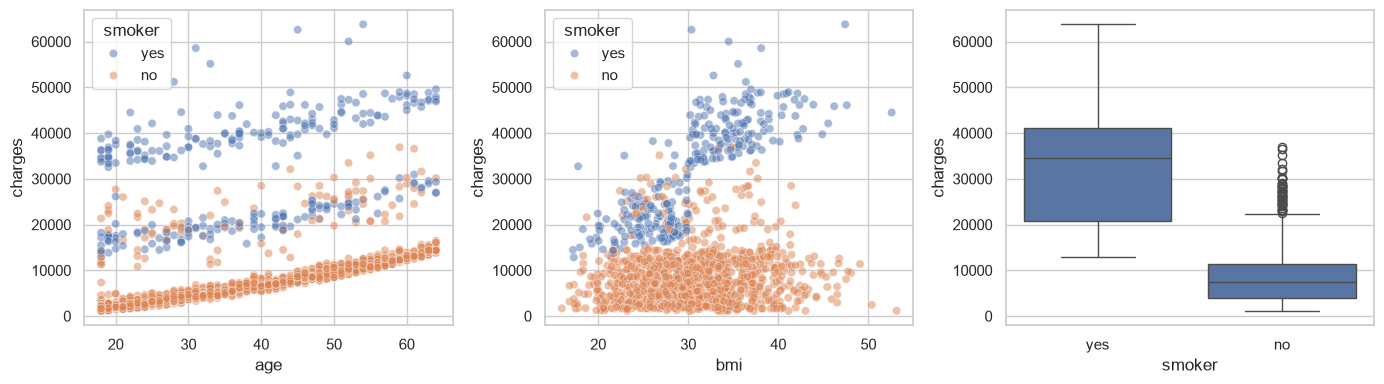

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
sns.scatterplot(data=data, x='age', y='charges', hue='smoker', alpha=0.5, ax=axes[0])
sns.scatterplot(data=data, x='bmi', y='charges', hue='smoker', alpha=0.5, ax=axes[1])
sns.boxplot(data=data, x='smoker', y='charges', ax=axes[2])
plt.tight_layout()
plt.show()

## Split, preprocessing, dan training

In [3]:
numeric_features = ['age', 'bmi', 'children']
categorical_features = ['sex', 'smoker', 'region']
X, y = data[numeric_features + categorical_features], data['charges']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
preprocess = ColumnTransformer([
    ('numeric', StandardScaler(), numeric_features),
    ('category', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False), categorical_features)
])
model = Pipeline([('preprocess', preprocess), ('regression', LinearRegression())])
model.fit(X_train, y_train)
assert set(X_train.index).isdisjoint(X_test.index)
print('Train:', X_train.shape, '| Test:', X_test.shape)

Train: (1069, 6) | Test: (268, 6)


## Prediksi dan evaluasi data uji

In [4]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
def regression_metrics(actual, predicted):
    return {'MAE': mean_absolute_error(actual, predicted),
            'MSE': mean_squared_error(actual, predicted),
            'RMSE': np.sqrt(mean_squared_error(actual, predicted)),
            'R-squared': r2_score(actual, predicted)}

y_pred = model.predict(X_test)
baseline = DummyRegressor(strategy='mean').fit(X_train, y_train)
evaluation = pd.DataFrame([
    regression_metrics(y_test, y_pred),
    regression_metrics(y_test, baseline.predict(X_test))
], index=['Multiple Linear Regression', 'Baseline rata-rata latih'])
display(evaluation.round(4))
display(pd.DataFrame({'Aktual': y_test, 'Prediksi': y_pred, 'Residual': y_test-y_pred}).head(10).round(2))
feature_names = model.named_steps['preprocess'].get_feature_names_out()
display(pd.DataFrame({'Fitur setelah transformasi': feature_names,
                      'Koefisien': model.named_steps['regression'].coef_}).round(2))

,MAE,MSE,RMSE,R-squared
Multiple Linear Regression,4177.0456,3.547802e+07,5956.3429,0.8069
Baseline rata-rata latih,9861.7979,1.852981e+08,13612.4260,-0.0084


,Aktual,Prediksi,Residual
899,8688.86,8143.69,545.16
1063,5708.87,5737.12,-28.25
1255,11436.74,14369.31,-2932.58
298,38746.36,31745.51,7000.84
237,4463.21,8962.39,-4499.18
481,9304.70,13149.72,-3845.02
240,38511.63,30446.76,8064.87
277,2150.47,1453.29,697.18
415,7345.73,10633.02,-3287.29
706,10264.44,11318.94,-1054.50


,Fitur setelah transformasi,Koefisien
0,numeric__age,3472.98
1,numeric__bmi,1927.83
2,numeric__children,636.50
3,category__sex_male,-101.54
4,category__smoker_yes,23077.76
5,category__region_northwest,-391.76
6,category__region_southeast,-838.92
7,category__region_southwest,-659.14


## Visualisasi dan analisis hasil

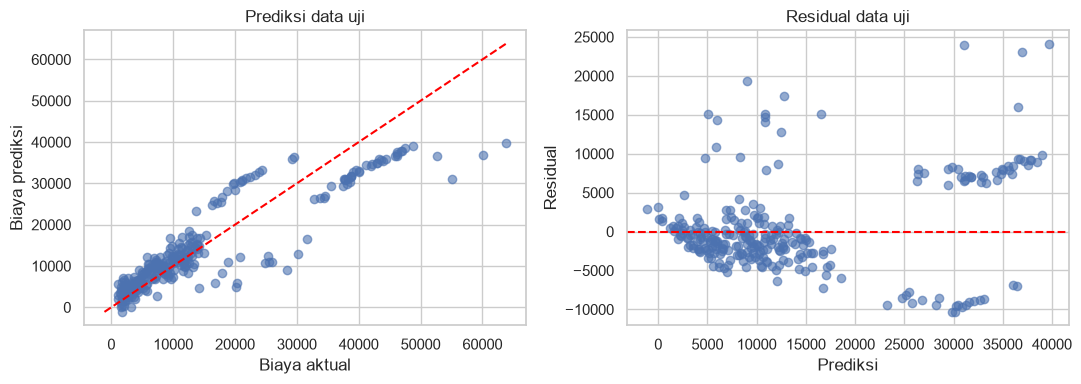

Model memperoleh **R² 0.8069**, **MAE 4,177.05**, dan **RMSE 5,956.34** pada data uji. Bandingkan dengan baseline untuk menilai manfaat fitur. Biaya perokok cenderung lebih tinggi pada EDA. Sebaran residual menunjukkan batas model aditif linier, termasuk kemungkinan interaksi BMI dan status merokok. Koefisien numerik ditafsirkan per satu simpangan baku karena fitur distandardisasi.

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(y_test, y_pred, alpha=0.6)
lo, hi = min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())
axes[0].plot([lo, hi], [lo, hi], '--', color='red')
axes[0].set(xlabel='Biaya aktual', ylabel='Biaya prediksi', title='Prediksi data uji')
axes[1].scatter(y_pred, y_test-y_pred, alpha=0.6)
axes[1].axhline(0, color='red', linestyle='--')
axes[1].set(xlabel='Prediksi', ylabel='Residual', title='Residual data uji')
plt.tight_layout()
plt.show()
score = evaluation.loc['Multiple Linear Regression']
display(Markdown(f'Model memperoleh **R² {score["R-squared"]:.4f}**, **MAE {score["MAE"]:,.2f}**, '
                 f'dan **RMSE {score["RMSE"]:,.2f}** pada data uji. '
                 'Bandingkan dengan baseline untuk menilai manfaat fitur. Biaya perokok cenderung lebih tinggi pada EDA. '
                 'Sebaran residual menunjukkan batas model aditif linier, termasuk kemungkinan interaksi BMI dan status merokok. '
                 'Koefisien numerik ditafsirkan per satu simpangan baku karena fitur distandardisasi.'))